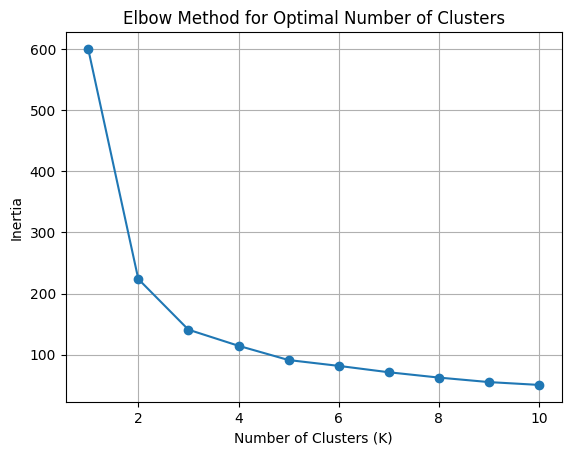

Inertia values:
[600.0, 223.73200573676343, 140.96581663074699, 114.61788585776677, 91.29544474066982, 81.75658187204954, 71.31982095188796, 62.61969485721661, 55.261841196034645, 50.62316902954045]


In [3]:
# Importing necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Step 1: Load the Iris dataset
df = pd.read_csv("Iris.csv")

# Step 2: Select features for clustering
# Remove Id column and Species column
X = df.iloc[:, 1:-1]

# Step 3: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 4: Apply Elbow Method
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Step 5: Plot Elbow Curve
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.grid(True)
plt.show()

# Step 6: Display inertia values
print("Inertia values:")
print(inertia)

First 5 rows of the dataset:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Dataset shape: (150, 6)

Selected Features:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2

WCSS Values:
[680.8244, 152.36870647733903, 78.94084142614602, 57.31787321428572, 46.535582051282056, 3

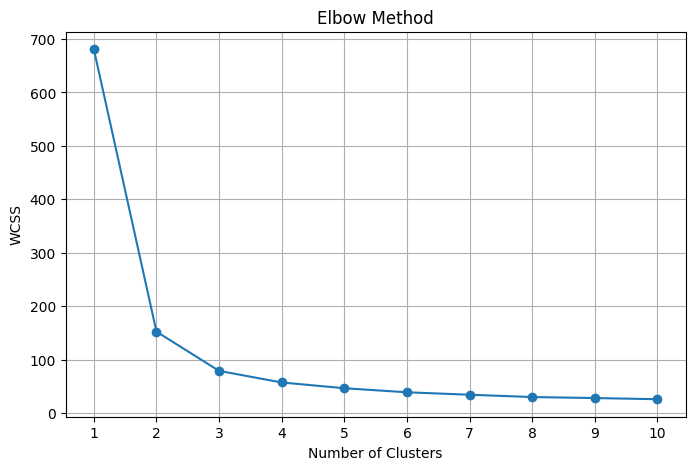


Cluster Assignments:
   Id      Species  Cluster
0   1  Iris-setosa        1
1   2  Iris-setosa        1
2   3  Iris-setosa        1
3   4  Iris-setosa        1
4   5  Iris-setosa        1
5   6  Iris-setosa        1
6   7  Iris-setosa        1
7   8  Iris-setosa        1
8   9  Iris-setosa        1
9  10  Iris-setosa        1

Number of Data Points in Each Cluster:
Cluster
0    62
1    50
2    38
Name: count, dtype: int64


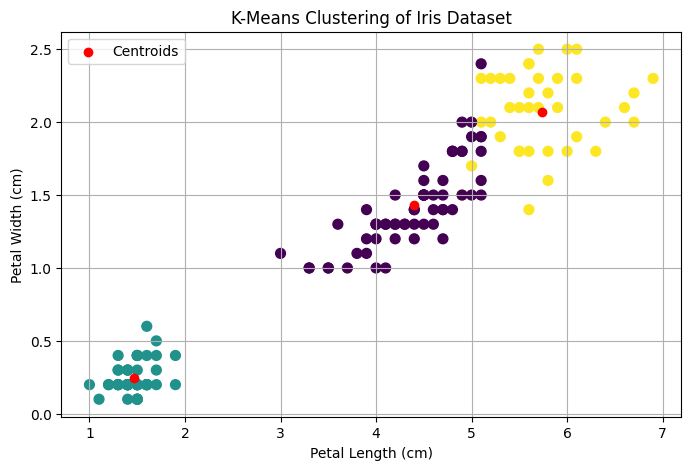

In [1]:
# Implementation of K-Means Clustering using Iris Dataset
# Determine optimal number of clusters using Elbow Method

# Step 1: Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Step 2: Load Dataset
data = pd.read_csv("Iris.csv")

print("First 5 rows of the dataset:")
print(data.head())

print("\nDataset shape:", data.shape)

# Step 3: Select Features
X = data[
    [
        "SepalLengthCm",
        "SepalWidthCm",
        "PetalLengthCm",
        "PetalWidthCm"
    ]
]

print("\nSelected Features:")
print(X.head())

# Step 4: Apply Elbow Method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

print("\nWCSS Values:")
print(wcss)

# Step 5: Plot Elbow Curve
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# Step 6: Apply K-Means with 3 Clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X)

data["Cluster"] = clusters

# Step 7: Display Cluster Assignments
print("\nCluster Assignments:")
print(data[["Id", "Species", "Cluster"]].head(10))

print("\nNumber of Data Points in Each Cluster:")
print(data["Cluster"].value_counts().sort_index())

# Step 8: Visualize Clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X["PetalLengthCm"],
    X["PetalWidthCm"],
    c=clusters,
    s=50
)

# Display Centroids
centers = kmeans.cluster_centers_

plt.scatter(
    centers[:, 2],
    centers[:, 3],
    c='red',
    label="Centroids"
)

plt.title("K-Means Clustering of Iris Dataset")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.grid(True)
plt.show()